In [ ]:
OPENAI_API_KEY=""
OPENAI_MODEL="gpt-5.6-luna"

In [ ]:
import os
from dotenv import load_dotenv

load_dotenv()

API_KEY = os.getenv("OPENAI_API_KEY",OPENAI_API_KEY)
MODEL_NAME = os.getenv("OPENAI_MODEL", OPENAI_MODEL)

if not API_KEY:
    raise ValueError("OPENAI_API_KEY is missing")

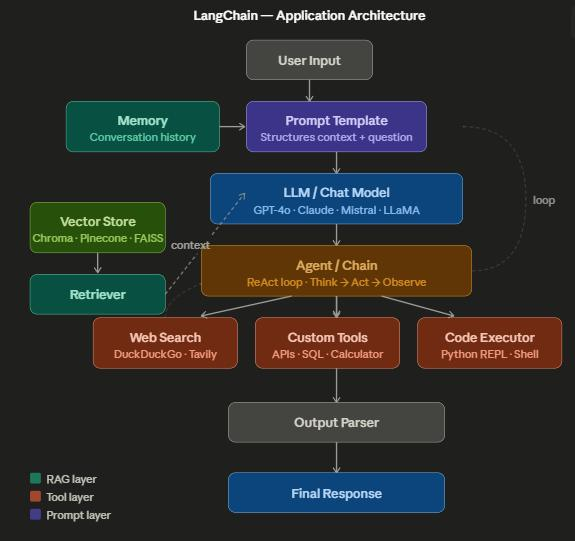

### Core Components

| Component | Responsibility|
| --- | --- |
|Chat model | Generates responses and tool-call requests|
|Prompt template |Builds model input from reusable templates|
|Messages | Represents system, user, assistant, and tool interactions|
|Output parser | Converts model output into a desired representation|
|Tools|Expose callable Python functions or external capabilities|
|Agent|Chooses actions and coordinates tools and model calls|
|Execution runtime|Runs the agent loop and manages state and results|

In [ ]:
!pip install langchain_openai -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.4/127.4 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.1/572.1 kB 9.2 MB/s eta 0:00:00


### Initialize a chat model

In [ ]:
from langchain_openai import ChatOpenAI

model = ChatOpenAI(
    model=MODEL_NAME,
    api_key=OPENAI_API_KEY,
    temperature=0,
    timeout=60,
    max_retries=2
)

response = model.invoke(
    "What is the difference between AI and ML?"
)

print(response.content)
print(response.content)
print(response.usage_metadata)

**Artificial Intelligence (AI)** is the broader concept of machines performing tasks that typically require human intelligence—such as reasoning, planning, understanding language, seeing, or making decisions.

**Machine Learning (ML)** is a subset of AI in which systems learn patterns from data and improve their performance without being explicitly programmed for every rule.

**Example:**
- **AI:** A self-driving car that perceives its surroundings, plans a route, and makes driving decisions.
- **ML:** The algorithms that learn to recognize pedestrians or predict traffic from large datasets.

In short: **AI is the goal or field; ML is one major way to achieve AI.** Deep learning is a further subset of ML using multilayer neural networks.
**Artificial Intelligence (AI)** is the broader concept of machines performing tasks that typically require human intelligence—such as reasoning, planning, understanding language, seeing, or making decisions.

**Machine Learning (ML)** is a subset of A

#### Batch Process

In [ ]:
questions = [
    "What is LangChain?",
    "What is an LLM?",
    "What is a tool in LangChain?"
]

results = model.batch(questions)

for question, answer in zip(questions, results):
    print("Question:", question)
    print("Answer:", answer.content)
    print("-" * 40)

Question: What is LangChain?
Answer: LangChain is an open-source framework for building applications powered by large language models (LLMs), such as chatbots, document-question answering systems, and AI agents.

It provides tools to:

- Connect LLMs to prompts, APIs, databases, and files
- Build multi-step workflows called chains
- Implement retrieval-augmented generation (RAG)
- Give models tools and let them decide which to use
- Manage conversation history and structured outputs
- Integrate with model providers such as OpenAI, Anthropic, and Google

For example, a LangChain application might retrieve relevant documents from a vector database, pass them to an LLM, and generate an answer based on those documents.

In short, LangChain helps developers connect language models to data, tools, and application logic.
----------------------------------------
Question: What is an LLM?
Answer: An **LLM** is a **Large Language Model**—an AI system trained on massive amounts of text to underst

#### Streaming

In [ ]:
for chunk in model.stream(
    "Explain agentic AI with an example."
):
    if isinstance(chunk.content, str):
        print(chunk.content, end="", flush=True)

**Agentic AI** is AI that can pursue a goal by deciding what steps to take, using tools, checking results, and adapting its plan—rather than only responding to a single prompt.

### Example: Travel-booking agent

Suppose you tell an agent:

> “Plan a three-day business trip to Chicago next month, keeping the total cost under $1,500.”

An agentic AI might:

1. Ask for missing details, such as preferred dates or airport.
2. Search flights and hotels using travel websites or APIs.
3. Compare options against your budget and preferences.
4. Build an itinerary.
5. Notice that a cheaper flight has a long layover and revise the plan.
6. Present the best choices.
7. With your approval, book the flights and hotel.
8. Add the itinerary to your calendar and notify you of changes.

The key feature is that it works toward an objective across multiple steps. A conventional chatbot might simply provide travel suggestions, while an agentic system can **plan, act, observe outcomes, and adjust**.

Agenti

### Prompt templates and messages

In [ ]:
from langchain_core.prompts import ChatPromptTemplate

prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        "You are an experienced {role}. "
        "Explain concepts clearly with practical examples."
    ),
    (
        "human",
        "Explain {topic} for someone with {experience} experience."
    )
])

messages = prompt.invoke({
    "role": "AI instructor",
    "topic": "RAG",
    "experience": "beginner"
})

print(messages)

messages=[SystemMessage(content='You are an experienced AI instructor. Explain concepts clearly with practical examples.', additional_kwargs={}, response_metadata={}), HumanMessage(content='Explain RAG for someone with beginner experience.', additional_kwargs={}, response_metadata={})]


#### Using message placeholder

In [ ]:
from langchain_core.prompts import (
    ChatPromptTemplate,
    MessagesPlaceholder
)
from langchain_core.messages import HumanMessage, AIMessage

prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        "You are a helpful Python tutor."
    ),
    MessagesPlaceholder("history"),
    ("human", "{question}")
])

history = [
    HumanMessage(content="What is a Python decorator?"),
    AIMessage(content="A decorator modifies a function's behavior.")
]

messages = prompt.invoke({
    "history": history,
    "question": "Show me a simple example."
})

print(messages)

messages=[SystemMessage(content='You are a helpful Python tutor.', additional_kwargs={}, response_metadata={}), HumanMessage(content='What is a Python decorator?', additional_kwargs={}, response_metadata={}), AIMessage(content="A decorator modifies a function's behavior.", additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='Show me a simple example.', additional_kwargs={}, response_metadata={})]


#### message types

In [ ]:
from langchain_core.messages import (
    SystemMessage,
    HumanMessage,
    AIMessage,
    ToolMessage
)

messages = [
    SystemMessage(content="You are a helpful assistant."),
    HumanMessage(content="What is 2 + 2?"),
    AIMessage(content="4")
]

print(messages)

[SystemMessage(content='You are a helpful assistant.', additional_kwargs={}, response_metadata={}), HumanMessage(content='What is 2 + 2?', additional_kwargs={}, response_metadata={}), AIMessage(content='4', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[])]


### Build a basic LCEL chain

In [ ]:
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

model = ChatOpenAI(
    model=MODEL_NAME,
    api_key=OPENAI_API_KEY,
    temperature=0
)

prompt = ChatPromptTemplate.from_template(
    "Explain {topic} to a beginner in 3 sentences."
)

parser = StrOutputParser()

chain = prompt | model | parser

In [ ]:
messages = prompt.invoke({
    "topic": "AI agents"
})

print(messages)

messages=[HumanMessage(content='Explain AI agents to a beginner in 3 sentences.', additional_kwargs={}, response_metadata={})]


In [ ]:
response = chain.invoke({
    "topic": "LangChain architecture"
})

print(response)

LangChain is a framework for building applications that use large language models (LLMs) by connecting them to prompts, tools, data sources, and memory.  
Its main building blocks include models that generate text, chains that organize steps, retrievers that find relevant information, and agents that decide which tools to use.  
Together, these components let you create applications such as chatbots, document question-answering systems, and automated task assistants.


#### Build a prompt chain with history

In [ ]:
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.messages import HumanMessage, AIMessage
from langchain_core.output_parsers import StrOutputParser

prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a concise AI/ML instructor."),
    MessagesPlaceholder("history"),
    ("human", "{question}")
])

chain = prompt | model | StrOutputParser()

history = [
    HumanMessage(content="What is RAG?"),
    AIMessage(content="RAG retrieves relevant information before generation.")
]

answer = chain.invoke({
    "history": history,
    "question": "Why is retrieval useful?"
})

print(answer)

Retrieval is useful because it gives the model relevant, up-to-date information from external sources before it generates an answer. This can:

- Reduce hallucinations
- Incorporate private or domain-specific knowledge
- Keep information current without retraining the model
- Support citations or links to source documents
- Improve accuracy on specialized questions


### Tools and function calling

#### Create a custom tool

In [ ]:
from langchain.tools import tool

@tool
def calculate_percentage(
    obtained_marks: float,
    total_marks: float
) -> float:
    """Calculate exam percentage from obtained and total marks."""
    if total_marks <= 0:
        raise ValueError("Total marks must be positive")

    return round(
        obtained_marks / total_marks * 100,
        2
    )

print(calculate_percentage.name)
print(calculate_percentage.description)
print(calculate_percentage.args_schema.model_json_schema())

calculate_percentage
Calculate exam percentage from obtained and total marks.
{'description': 'Calculate exam percentage from obtained and total marks.', 'properties': {'obtained_marks': {'title': 'Obtained Marks', 'type': 'number'}, 'total_marks': {'title': 'Total Marks', 'type': 'number'}}, 'required': ['obtained_marks', 'total_marks'], 'title': 'calculate_percentage', 'type': 'object'}


In [ ]:
# bind tools with the model

from langchain_openai import ChatOpenAI

model = ChatOpenAI(
    model=MODEL_NAME,
    api_key=OPENAI_API_KEY,
    temperature=0,
    reasoning={
        "effort": "medium"
    },
    timeout=60,
    max_retries=2
)

tools = [calculate_percentage]

model_with_tools = model.bind_tools(tools)

response = model_with_tools.invoke(
    "I scored 425 marks out of 500. Calculate my percentage."
)

print(response)
print(response.tool_calls)

content=[{'id': 'rs_04ad3e6cdeabc366006ab79486fea887d09d9c77395b41d6a8', 'summary': [], 'type': 'reasoning', 'content': [], 'encrypted_content': 'gAAAAABqt5SH0BqNBaEI2QuOpRhfCP1JtieVaYEN5FTHcUgfNcHRwJpXd26IxSw3kh7EHJsHYiDTngJ4FUWkut5Uz-p7c0o7EMJQivjj7eZV75V-Gq9EmtiZZInbVqswWZxsmVxVHs4fELjI_62jUuoUyiGrrw6SYFO49vrJqYGb4Bx2UnhWHvYBU2XRIUwg3qsp-11C5yl6nQvOWceJ9-D20JDFSRZVo6br8388KiOIUV2XJlEr3B7ZWcFwtIzn-rf3m_idcLl-gj7Qdn1OBoa-3EC6H4RDzAvTzAezIopyxL4DUieDtUB3LOSsQH_JDhy2eeE8StdYUGyPgKN_Bb_FyxO_Y8cS8jjYgUIJfvbkex4ZyrwMiwO7EZ54jBZbji7KJF52IdJvoYSkp4Pki1BPl54Hhp_hNMT-o8k1Meo0aGjv1kLoyT5dJxnJhRqTPb_opRYzJjHu8E5XMUoSy7Nci6G-Q8FuD8oSIbhZs6jJdcJm2YsDEJ7lPE9WY8A3_xItE2hDxDqP555_DzxvIHB0zG42fbOvblEiH3mOdrxgrw9ahhjR-Yw7dngVf0Z0aodsO5abeTU-kBcB3avGBKCxz4xLxLcab0a5naW9pHYqDXiMD9kpf2PYzqcTWc8yxVM36ZCxc88zm_8wDm0gP5yEl5utG8rW_7rwjdQdvRESpOYFOfLfCw6HzlMSTdlH9o1X2HOaa89eRWhTT9x0aMlRp1FBNStIKg7oznx4QSAIvgHBuUULPKBwMOhWrEyk663JQjOkU72VBlsvEiUV8GuZd_lulJCaV_AGGv5XPubzsnIswpdcWd8nXeUlLGUkLr8pqu1T5iOHBWPy_BZtpE

In [ ]:
# manual execution

from langchain_core.messages import ToolMessage

response = model_with_tools.invoke(
    "Calculate the percentage for 425 out of 500."
)

tool_call = response.tool_calls[0]

tool_result = calculate_percentage.invoke(
    tool_call["args"]
)

tool_message = ToolMessage(
    content=str(tool_result),
    tool_call_id=tool_call["id"]
)

print(tool_message)

content='85.0' tool_call_id='call_yUAItj7l0259ije6m3Y3c6XW'


In [ ]:
# Return the tool result to the model
final_response = model_with_tools.invoke([
    HumanMessage(
        content="Calculate the percentage for 425 out of 500."
    ),
    response,
    tool_message
])

print(final_response.content)

[{'type': 'text', 'text': '425 out of 500 is **85%**.', 'annotations': [], 'id': 'msg_049a4eaf06bf0337006ab794c45fd087d09d66b7f6bc170d52', 'phase': 'final_answer'}]


In [ ]:
# example
from langchain.tools import tool

@tool
def get_exam_details(exam_name: str) -> str:
    """Return exam details for supported competitive exams."""
    exams = {
        "TNPSC": "Tamil Nadu Public Service Commission exams",
        "UPSC": "Union Public Service Commission Civil Services",
        "SSC": "Staff Selection Commission examinations",
        "Banking": "Banking recruitment examinations"
    }

    return exams.get(
        exam_name,
        "Exam details are not available in this demo."
    )


@tool
def calculate_study_hours(
    days_remaining: int,
    daily_hours: float
) -> float:
    """Calculate total available study hours."""
    if days_remaining < 0 or daily_hours < 0:
        raise ValueError("Inputs cannot be negative")

    return days_remaining * daily_hours

In [ ]:
tools = [
    calculate_percentage,
    get_exam_details,
    calculate_study_hours
]

model_with_tools = model.bind_tools(tools)

### Agents

In [ ]:
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent

model = ChatOpenAI(
    model=MODEL_NAME,
    api_key=OPENAI_API_KEY,
    temperature=0,
    reasoning={
        "effort": "medium"
    },
    timeout=60,
    max_retries=2
)


agent = create_agent(
    model=model,
    tools=[
        calculate_percentage,
        get_exam_details,
        calculate_study_hours
    ],
    system_prompt="""
    You are an AI exam preparation assistant.

    Help users understand their exams and plan study time.

    Use the available tools whenever calculations
    or supported exam information are needed.

    Never invent a calculated result when a tool
    is available to perform the calculation.
    """
)

result = agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": """
            I am preparing for TNPSC.
            I have 45 days remaining and can study
            4 hours daily.

            I scored 360 out of 450 in a mock test.
            Tell me my total available study hours,
            mock-test percentage, and exam details.
            """
        }
    ]
})

print(result["messages"][-1].content)

[{'type': 'text', 'text': '- **Total available study hours:** 180 hours  \n  *(45 days × 4 hours per day)*\n\n- **Mock-test percentage:** 80%  \n  *(360 ÷ 450 × 100)*\n\n- **Exam details:** TNPSC stands for the **Tamil Nadu Public Service Commission**, which conducts recruitment examinations for various posts in the Tamil Nadu state government. Different TNPSC exams include **Group I, Group II/IIA, Group IV, and other specialized recruitment exams**.', 'annotations': [], 'id': 'msg_0096209b56e97316006ab798ea3e1887d080df529fab214419', 'phase': 'final_answer'}]


Diagram options

![](data\:image/svg+xml;utf8,%3Csvg%20id%3D%22mermaid-_r_ra_%22%20width%3D%22283.796875%22%20xmlns%3D%22http%3A%2F%2Fwww.w3.org%2F2000%2Fsvg%22%20class%3D%22flowchart%22%20height%3D%22602.0052490234375%22%20viewBox%3D%224%204%20283.796875%20602.0052490234375%22%20role%3D%22graphics-document%20document%22%20aria-roledescription%3D%22flowchart-v2%22%3E%3Cstyle%3E%23mermaid-_r_ra_%7Bfont-family%3A%22-apple-system%22%2C%22BlinkMacSystemFont%22%2C%22Segoe%20UI%22%2C%22Roboto%22%2C%22Oxygen%22%2C%22Ubuntu%22%2C%22Cantarell%22%2C%22Helvetica%20Neue%22%2C%22Arial%22%2C%22sans-serif%22%3Bfont-size%3A14px%3Bfill%3Argb\(13%2C%2013%2C%2013\)%3B%7D%40keyframes%20edge-animation-frame%7Bfrom%7Bstroke-dashoffset%3A0%3B%7D%7D%40keyframes%20dash%7Bto%7Bstroke-dashoffset%3A0%3B%7D%7D%23mermaid-_r_ra_%20.edge-animation-slow%7Bstroke-dasharray%3A9%2C5!important%3Bstroke-dashoffset%3A900%3Banimation%3Adash%2050s%20linear%20infinite%3Bstroke-linecap%3Around%3B%7D%23mermaid-_r_ra_%20.edge-animation-fast%7Bstroke-dasharray%3A9%2C5!important%3Bstroke-dashoffset%3A900%3Banimation%3Adash%2020s%20linear%20infinite%3Bstroke-linecap%3Around%3B%7D%23mermaid-_r_ra_%20.error-icon%7Bfill%3Argb\(249%2C%20249%2C%20249\)%3B%7D%23mermaid-_r_ra_%20.error-text%7Bfill%3Argb\(13%2C%2013%2C%2013\)%3Bstroke%3Argb\(13%2C%2013%2C%2013\)%3B%7D%23mermaid-_r_ra_%20.edge-thickness-normal%7Bstroke-width%3A1px%3B%7D%23mermaid-_r_ra_%20.edge-thickness-thick%7Bstroke-width%3A3.5px%3B%7D%23mermaid-_r_ra_%20.edge-pattern-solid%7Bstroke-dasharray%3A0%3B%7D%23mermaid-_r_ra_%20.edge-thickness-invisible%7Bstroke-width%3A0%3Bfill%3Anone%3B%7D%23mermaid-_r_ra_%20.edge-pattern-dashed%7Bstroke-dasharray%3A3%3B%7D%23mermaid-_r_ra_%20.edge-pattern-dotted%7Bstroke-dasharray%3A2%3B%7D%23mermaid-_r_ra_%20.marker%7Bfill%3Argb\(93%2C%2093%2C%2093\)%3Bstroke%3Argb\(93%2C%2093%2C%2093\)%3B%7D%23mermaid-_r_ra_%20.marker.cross%7Bstroke%3Argb\(93%2C%2093%2C%2093\)%3B%7D%23mermaid-_r_ra_%20svg%7Bfont-family%3A%22-apple-system%22%2C%22BlinkMacSystemFont%22%2C%22Segoe%20UI%22%2C%22Roboto%22%2C%22Oxygen%22%2C%22Ubuntu%22%2C%22Cantarell%22%2C%22Helvetica%20Neue%22%2C%22Arial%22%2C%22sans-serif%22%3Bfont-size%3A14px%3B%7D%23mermaid-_r_ra_%20p%7Bmargin%3A0%3B%7D%23mermaid-_r_ra_%20.label%7Bfont-family%3A%22-apple-system%22%2C%22BlinkMacSystemFont%22%2C%22Segoe%20UI%22%2C%22Roboto%22%2C%22Oxygen%22%2C%22Ubuntu%22%2C%22Cantarell%22%2C%22Helvetica%20Neue%22%2C%22Arial%22%2C%22sans-serif%22%3Bcolor%3Argb\(13%2C%2013%2C%2013\)%3B%7D%23mermaid-_r_ra_%20.cluster-label%20text%7Bfill%3Argb\(13%2C%2013%2C%2013\)%3B%7D%23mermaid-_r_ra_%20.cluster-label%20span%7Bcolor%3Argb\(13%2C%2013%2C%2013\)%3B%7D%23mermaid-_r_ra_%20.cluster-label%20span%20p%7Bbackground-color%3Atransparent%3B%7D%23mermaid-_r_ra_%20.label%20text%2C%23mermaid-_r_ra_%20span%7Bfill%3Argb\(13%2C%2013%2C%2013\)%3Bcolor%3Argb\(13%2C%2013%2C%2013\)%3B%7D%23mermaid-_r_ra_%20.node%20rect%2C%23mermaid-_r_ra_%20.node%20circle%2C%23mermaid-_r_ra_%20.node%20ellipse%2C%23mermaid-_r_ra_%20.node%20polygon%2C%23mermaid-_r_ra_%20.node%20path%7Bfill%3Argb\(250%2C%20232%2C%20222\)%3Bstroke%3Argb\(239%2C%20139%2C%2087\)%3Bstroke-width%3A1px%3B%7D%23mermaid-_r_ra_%20.rough-node%20.label%20text%2C%23mermaid-_r_ra_%20.node%20.label%20text%2C%23mermaid-_r_ra_%20.image-shape%20.label%2C%23mermaid-_r_ra_%20.icon-shape%20.label%7Btext-anchor%3Amiddle%3B%7D%23mermaid-_r_ra_%20.node%20.katex%20path%7Bfill%3A%23000%3Bstroke%3A%23000%3Bstroke-width%3A1px%3B%7D%23mermaid-_r_ra_%20.rough-node%20.label%2C%23mermaid-_r_ra_%20.node%20.label%2C%23mermaid-_r_ra_%20.image-shape%20.label%2C%23mermaid-_r_ra_%20.icon-shape%20.label%7Btext-align%3Acenter%3B%7D%23mermaid-_r_ra_%20.node.clickable%7Bcursor%3Apointer%3B%7D%23mermaid-_r_ra_%20.root%20.anchor%20path%7Bfill%3Argb\(93%2C%2093%2C%2093\)!important%3Bstroke-width%3A0%3Bstroke%3Argb\(93%2C%2093%2C%2093\)%3B%7D%23mermaid-_r_ra_%20.arrowheadPath%7Bfill%3Argb\(93%2C%2093%2C%2093\)%3B%7D%23mermaid-_r_ra_%20.edgePath%20.path%7Bstroke%3Argb\(93%2C%2093%2C%2093\)%3Bstroke-width%3A2.0px%3B%7D%23mermaid-_r_ra_%20.flowchart-link%7Bstroke%3Argb\(93%2C%2093%2C%2093\)%3Bfill%3Anone%3B%7D%23mermaid-_r_ra_%20.edgeLabel%7Bbackground-color%3Argb\(252%2C%20252%2C%20252\)%3Btext-align%3Acenter%3B%7D%23mermaid-_r_ra_%20.edgeLabel%20p%7Bbackground-color%3Argb\(252%2C%20252%2C%20252\)%3B%7D%23mermaid-_r_ra_%20.edgeLabel%20rect%7Bopacity%3A0.5%3Bbackground-color%3Argb\(252%2C%20252%2C%20252\)%3Bfill%3Argb\(252%2C%20252%2C%20252\)%3B%7D%23mermaid-_r_ra_%20.labelBkg%7Bbackground-color%3Argba\(252%2C%20252%2C%20252%2C%200.5\)%3B%7D%23mermaid-_r_ra_%20.cluster%20rect%7Bfill%3Argb\(249%2C%20249%2C%20249\)%3Bstroke%3Argba\(0%2C%200%2C%200%2C%200.05\)%3Bstroke-width%3A1px%3B%7D%23mermaid-_r_ra_%20.cluster%20text%7Bfill%3Argb\(13%2C%2013%2C%2013\)%3B%7D%23mermaid-_r_ra_%20.cluster%20span%7Bcolor%3Argb\(13%2C%2013%2C%2013\)%3B%7D%23mermaid-_r_ra_%20div.mermaidTooltip%7Bposition%3Aabsolute%3Btext-align%3Acenter%3Bmax-width%3A200px%3Bpadding%3A2px%3Bfont-family%3A%22-apple-system%22%2C%22BlinkMacSystemFont%22%2C%22Segoe%20UI%22%2C%22Roboto%22%2C%22Oxygen%22%2C%22Ubuntu%22%2C%22Cantarell%22%2C%22Helvetica%20Neue%22%2C%22Arial%22%2C%22sans-serif%22%3Bfont-size%3A12px%3Bbackground%3Argb\(249%2C%20249%2C%20249\)%3Bborder%3A1px%20solid%20rgba\(0%2C%200%2C%200%2C%200.05\)%3Bborder-radius%3A2px%3Bpointer-events%3Anone%3Bz-index%3A100%3B%7D%23mermaid-_r_ra_%20.flowchartTitleText%7Btext-anchor%3Amiddle%3Bfont-size%3A18px%3Bfill%3Argb\(13%2C%2013%2C%2013\)%3B%7D%23mermaid-_r_ra_%20rect.text%7Bfill%3Anone%3Bstroke-width%3A0%3B%7D%23mermaid-_r_ra_%20.icon-shape%2C%23mermaid-_r_ra_%20.image-shape%7Bbackground-color%3Argb\(252%2C%20252%2C%20252\)%3Btext-align%3Acenter%3B%7D%23mermaid-_r_ra_%20.icon-shape%20p%2C%23mermaid-_r_ra_%20.image-shape%20p%7Bbackground-color%3Argb\(252%2C%20252%2C%20252\)%3Bpadding%3A2px%3B%7D%23mermaid-_r_ra_%20.icon-shape%20rect%2C%23mermaid-_r_ra_%20.image-shape%20rect%7Bopacity%3A0.5%3Bbackground-color%3Argb\(252%2C%20252%2C%20252\)%3Bfill%3Argb\(252%2C%20252%2C%20252\)%3B%7D%23mermaid-_r_ra_%20.label-icon%7Bdisplay%3Ainline-block%3Bheight%3A1em%3Boverflow%3Avisible%3Bvertical-align%3A-0.125em%3B%7D%23mermaid-_r_ra_%20.node%20.label-icon%20path%7Bfill%3AcurrentColor%3Bstroke%3Arevert%3Bstroke-width%3Arevert%3B%7D%23mermaid-_r_ra_%20.node%20text%7Bfont-size%3A16px%3Bfont-weight%3A600%3Bletter-spacing%3A-0.32px%3Bfill%3A%236d2e0f%3B%7D%23mermaid-_r_ra_%20.edgeLabels%20text%7Bfont-size%3A13px%3Bfont-weight%3A600%3Bletter-spacing%3A-0.08px%3Bfill%3A%236d2e0f%3B%7D%23mermaid-_r_ra_%20.node%20tspan%5Bfont-weight%3D%22normal%22%5D%2C%23mermaid-_r_ra_%20.edgeLabels%20tspan%5Bfont-weight%3D%22normal%22%5D%7Bfont-weight%3A600%3B%7D%23mermaid-_r_ra_%20.edgeLabel%20.label%20rect%7Bopacity%3A1%3Brx%3A13px%3Bry%3A13px%3Bfill%3A%23fff5f0%3Bstroke%3Argb\(229%2C%20208%2C%20195\)%3Bstroke-width%3A1px%3B%7D%23mermaid-_r_ra_%20.node%20rect%2C%23mermaid-_r_ra_%20.node%20circle%2C%23mermaid-_r_ra_%20.node%20ellipse%2C%23mermaid-_r_ra_%20.node%20polygon%2C%23mermaid-_r_ra_%20.node%20path%7Bfill%3Argb\(255%2C%20231%2C%20217\)%3Bstroke%3Argba\(0%2C%200%2C%200%2C%200.1\)%3Bstroke-width%3A1px%3B%7D%23mermaid-_r_ra_%20.node%20rect%7Brx%3A16px%3Bry%3A16px%3B%7D%23mermaid-_r_ra_%20.node.mermaid-decision%20.label-container%7Bfill%3A%23fff5f0%3Bstroke%3Argb\(229%2C%20208%2C%20195\)%3Bstroke-dasharray%3A2%202%3B%7D%23mermaid-_r_ra_%20.edgePaths%20.flowchart-link%7Bstroke%3Argb\(229%2C%20208%2C%20195\)%3Bstroke-width%3A1px%3Bstroke-linecap%3Around%3Bstroke-linejoin%3Around%3B%7D%23mermaid-_r_ra_%20.marker%7Bfill%3Argb\(229%2C%20208%2C%20195\)%3Bstroke%3Argb\(229%2C%20208%2C%20195\)%3B%7D%23mermaid-_r_ra_%20.node%7Bcolor-scheme%3Alight%3B%7D%23mermaid-_r_ra_%20%3Aroot%7B--mermaid-font-family%3A%22-apple-system%22%2C%22BlinkMacSystemFont%22%2C%22Segoe%20UI%22%2C%22Roboto%22%2C%22Oxygen%22%2C%22Ubuntu%22%2C%22Cantarell%22%2C%22Helvetica%20Neue%22%2C%22Arial%22%2C%22sans-serif%22%3B%7D%3C%2Fstyle%3E%3Cg%3E%3Cmarker%20id%3D%22mermaid-_r_ra__flowchart-v2-pointEnd%22%20class%3D%22marker%20flowchart-v2%22%20viewBox%3D%22-5%20-5%2010%2010%22%20refX%3D%220%22%20refY%3D%220%22%20markerUnits%3D%22userSpaceOnUse%22%20markerWidth%3D%2210%22%20markerHeight%3D%2210%22%20orient%3D%22auto%22%3E%3Cpath%20d%3D%22M%200%200%20L%204%200%20M%200.8180194846605362%20-3.181980515339464%20L%204%200%20L%200.8180194846605362%203.181980515339464%22%20class%3D%22arrowMarkerPath%22%20style%3D%22stroke-width%3A%201%3B%20stroke-dasharray%3A%20none%3B%20fill%3A%20none%3B%20stroke-linecap%3A%20round%3B%20stroke-linejoin%3A%20round%3B%22%3E%3C%2Fpath%3E%3C%2Fmarker%3E%3Cmarker%20id%3D%22mermaid-_r_ra__flowchart-v2-pointStart%22%20class%3D%22marker%20flowchart-v2%22%20viewBox%3D%22-5%20-5%2010%2010%22%20refX%3D%220%22%20refY%3D%220%22%20markerUnits%3D%22userSpaceOnUse%22%20markerWidth%3D%2210%22%20markerHeight%3D%2210%22%20orient%3D%22auto%22%3E%3Cpath%20d%3D%22M%200%200%20L%20-4%200%20M%20-0.8180194846605362%20-3.181980515339464%20L%20-4%200%20L%20-0.8180194846605362%203.181980515339464%22%20class%3D%22arrowMarkerPath%22%20style%3D%22stroke-width%3A%201%3B%20stroke-dasharray%3A%20none%3B%20fill%3A%20none%3B%20stroke-linecap%3A%20round%3B%20stroke-linejoin%3A%20round%3B%22%3E%3C%2Fpath%3E%3C%2Fmarker%3E%3Cmarker%20id%3D%22mermaid-_r_ra__flowchart-v2-circleEnd%22%20class%3D%22marker%20flowchart-v2%22%20viewBox%3D%220%200%2010%2010%22%20refX%3D%2211%22%20refY%3D%225%22%20markerUnits%3D%22userSpaceOnUse%22%20markerWidth%3D%2211%22%20markerHeight%3D%2211%22%20orient%3D%22auto%22%3E%3Ccircle%20cx%3D%225%22%20cy%3D%225%22%20r%3D%225%22%20class%3D%22arrowMarkerPath%22%20style%3D%22stroke-width%3A%201%3B%20stroke-dasharray%3A%201%2C%200%3B%22%3E%3C%2Fcircle%3E%3C%2Fmarker%3E%3Cmarker%20id%3D%22mermaid-_r_ra__flowchart-v2-circleStart%22%20class%3D%22marker%20flowchart-v2%22%20viewBox%3D%220%200%2010%2010%22%20refX%3D%22-1%22%20refY%3D%225%22%20markerUnits%3D%22userSpaceOnUse%22%20markerWidth%3D%2211%22%20markerHeight%3D%2211%22%20orient%3D%22auto%22%3E%3Ccircle%20cx%3D%225%22%20cy%3D%225%22%20r%3D%225%22%20class%3D%22arrowMarkerPath%22%20style%3D%22stroke-width%3A%201%3B%20stroke-dasharray%3A%201%2C%200%3B%22%3E%3C%2Fcircle%3E%3C%2Fmarker%3E%3Cmarker%20id%3D%22mermaid-_r_ra__flowchart-v2-crossEnd%22%20class%3D%22marker%20cross%20flowchart-v2%22%20viewBox%3D%220%200%2011%2011%22%20refX%3D%2212%22%20refY%3D%225.2%22%20markerUnits%3D%22userSpaceOnUse%22%20markerWidth%3D%2211%22%20markerHeight%3D%2211%22%20orient%3D%22auto%22%3E%3Cpath%20d%3D%22M%201%2C1%20l%209%2C9%20M%2010%2C1%20l%20-9%2C9%22%20class%3D%22arrowMarkerPath%22%20style%3D%22stroke-width%3A%202%3B%20stroke-dasharray%3A%201%2C%200%3B%22%3E%3C%2Fpath%3E%3C%2Fmarker%3E%3Cmarker%20id%3D%22mermaid-_r_ra__flowchart-v2-crossStart%22%20class%3D%22marker%20cross%20flowchart-v2%22%20viewBox%3D%220%200%2011%2011%22%20refX%3D%22-1%22%20refY%3D%225.2%22%20markerUnits%3D%22userSpaceOnUse%22%20markerWidth%3D%2211%22%20markerHeight%3D%2211%22%20orient%3D%22auto%22%3E%3Cpath%20d%3D%22M%201%2C1%20l%209%2C9%20M%2010%2C1%20l%20-9%2C9%22%20class%3D%22arrowMarkerPath%22%20style%3D%22stroke-width%3A%202%3B%20stroke-dasharray%3A%201%2C%200%3B%22%3E%3C%2Fpath%3E%3C%2Fmarker%3E%3C%2Fg%3E%3Cg%20class%3D%22subgraphs%22%3E%3C%2Fg%3E%3Cg%20class%3D%22nodes%22%3E%3Cg%20class%3D%22node%20default%22%20id%3D%22flowchart-A-0%22%20transform%3D%22translate\(145.8984375%2C%2054.599998474121094\)%22%3E%3Crect%20class%3D%22basic%20label-container%22%20style%3D%22fill%3A%23f5f5f5%20!important%3Bstroke%3A%23ddd%20!important%22%20x%3D%22-118.046875%22%20y%3D%22-42.599998474121094%22%20width%3D%22236.09375%22%20height%3D%2285.19999694824219%22%3E%3C%2Frect%3E%3Cg%20class%3D%22label%22%20style%3D%22color%3A%23111%20!important%22%20transform%3D%22translate\(0%2C%20-26.599998474121094\)%22%3E%3Crect%3E%3C%2Frect%3E%3Cg%3E%3Crect%20class%3D%22background%22%20style%3D%22stroke%3A%20none%22%3E%3C%2Frect%3E%3Ctext%20y%3D%22-10.1%22%20style%3D%22fill%3A%23111%20!important%22%3E%3Ctspan%20class%3D%22text-outer-tspan%22%20x%3D%220%22%20y%3D%22-0.1em%22%20dy%3D%221.1em%22%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3EUser%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20request%3C%2Ftspan%3E%3C%2Ftspan%3E%3Ctspan%20class%3D%22text-outer-tspan%22%20x%3D%220%22%20y%3D%221em%22%20dy%3D%221.1em%22%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3EExam%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20details%2C%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20available%3C%2Ftspan%3E%3C%2Ftspan%3E%3Ctspan%20class%3D%22text-outer-tspan%22%20x%3D%220%22%20y%3D%222.1em%22%20dy%3D%221.1em%22%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3Etime%2C%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20mock%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20score%3C%2Ftspan%3E%3C%2Ftspan%3E%3C%2Ftext%3E%3C%2Fg%3E%3C%2Fg%3E%3C%2Fg%3E%3Cg%20class%3D%22node%20default%22%20id%3D%22flowchart-B-1%22%20transform%3D%22translate\(145.8984375%2C%20179.80261993408203\)%22%3E%3Crect%20class%3D%22basic%20label-container%22%20style%3D%22fill%3A%23e8eefc%20!important%3Bstroke%3A%23ddd%20!important%22%20x%3D%22-133.8671875%22%20y%3D%22-42.602622985839844%22%20width%3D%22267.734375%22%20height%3D%2285.20524597167969%22%3E%3C%2Frect%3E%3Cg%20class%3D%22label%22%20style%3D%22color%3A%23111%20!important%22%20transform%3D%22translate\(0%2C%20-26.602622985839844\)%22%3E%3Crect%3E%3C%2Frect%3E%3Cg%3E%3Crect%20class%3D%22background%22%20style%3D%22stroke%3A%20none%22%3E%3C%2Frect%3E%3Ctext%20y%3D%22-10.1%22%20style%3D%22fill%3A%23111%20!important%22%3E%3Ctspan%20class%3D%22text-outer-tspan%22%20x%3D%220%22%20y%3D%22-0.1em%22%20dy%3D%221.1em%22%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3ELLM%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20decides%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20on%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20tool%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20calls%3C%2Ftspan%3E%3C%2Ftspan%3E%3Ctspan%20class%3D%22text-outer-tspan%22%20x%3D%220%22%20y%3D%221em%22%20dy%3D%221.1em%22%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3EChoose%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20appropriate%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20tool\(s\)%3C%2Ftspan%3E%3C%2Ftspan%3E%3Ctspan%20class%3D%22text-outer-tspan%22%20x%3D%220%22%20y%3D%222.1em%22%20dy%3D%221.1em%22%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3Eand%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20arguments%3C%2Ftspan%3E%3C%2Ftspan%3E%3C%2Ftext%3E%3C%2Fg%3E%3C%2Fg%3E%3C%2Fg%3E%3Cg%20class%3D%22node%20default%22%20id%3D%22flowchart-C-2%22%20transform%3D%22translate\(145.8984375%2C%20305.00524139404297\)%22%3E%3Crect%20class%3D%22basic%20label-container%22%20style%3D%22fill%3A%23e4f4ee%20!important%3Bstroke%3A%23ddd%20!important%22%20x%3D%22-122.3984375%22%20y%3D%22-42.599998474121094%22%20width%3D%22244.796875%22%20height%3D%2285.19999694824219%22%3E%3C%2Frect%3E%3Cg%20class%3D%22label%22%20style%3D%22color%3A%23111%20!important%22%20transform%3D%22translate\(0%2C%20-26.599998474121094\)%22%3E%3Crect%3E%3C%2Frect%3E%3Cg%3E%3Crect%20class%3D%22background%22%20style%3D%22stroke%3A%20none%22%3E%3C%2Frect%3E%3Ctext%20y%3D%22-10.1%22%20style%3D%22fill%3A%23111%20!important%22%3E%3Ctspan%20class%3D%22text-outer-tspan%22%20x%3D%220%22%20y%3D%22-0.1em%22%20dy%3D%221.1em%22%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3EExecute%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20tools%3C%2Ftspan%3E%3C%2Ftspan%3E%3Ctspan%20class%3D%22text-outer-tspan%22%20x%3D%220%22%20y%3D%221em%22%20dy%3D%221.1em%22%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3EPython%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20functions%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20return%3C%2Ftspan%3E%3C%2Ftspan%3E%3Ctspan%20class%3D%22text-outer-tspan%22%20x%3D%220%22%20y%3D%222.1em%22%20dy%3D%221.1em%22%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3Eactual%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20results%3C%2Ftspan%3E%3C%2Ftspan%3E%3C%2Ftext%3E%3C%2Fg%3E%3C%2Fg%3E%3C%2Fg%3E%3Cg%20class%3D%22node%20default%22%20id%3D%22flowchart-D-3%22%20transform%3D%22translate\(145.8984375%2C%20430.20523834228516\)%22%3E%3Crect%20class%3D%22basic%20label-container%22%20style%3D%22fill%3A%23e8eefc%20!important%3Bstroke%3A%23ddd%20!important%22%20x%3D%22-133.8984375%22%20y%3D%22-42.599998474121094%22%20width%3D%22267.796875%22%20height%3D%2285.19999694824219%22%3E%3C%2Frect%3E%3Cg%20class%3D%22label%22%20style%3D%22color%3A%23111%20!important%22%20transform%3D%22translate\(0%2C%20-26.599998474121094\)%22%3E%3Crect%3E%3C%2Frect%3E%3Cg%3E%3Crect%20class%3D%22background%22%20style%3D%22stroke%3A%20none%22%3E%3C%2Frect%3E%3Ctext%20y%3D%22-10.1%22%20style%3D%22fill%3A%23111%20!important%22%3E%3Ctspan%20class%3D%22text-outer-tspan%22%20x%3D%220%22%20y%3D%22-0.1em%22%20dy%3D%221.1em%22%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3ELLM%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20observes%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20tool%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20results%3C%2Ftspan%3E%3C%2Ftspan%3E%3Ctspan%20class%3D%22text-outer-tspan%22%20x%3D%220%22%20y%3D%221em%22%20dy%3D%221.1em%22%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3EDecide%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20whether%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20more%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20tools%3C%2Ftspan%3E%3C%2Ftspan%3E%3Ctspan%20class%3D%22text-outer-tspan%22%20x%3D%220%22%20y%3D%222.1em%22%20dy%3D%221.1em%22%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3Eare%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20needed%3C%2Ftspan%3E%3C%2Ftspan%3E%3C%2Ftext%3E%3C%2Fg%3E%3C%2Fg%3E%3C%2Fg%3E%3Cg%20class%3D%22node%20default%22%20id%3D%22flowchart-E-4%22%20transform%3D%22translate\(145.8984375%2C%20555.4052352905273\)%22%3E%3Crect%20class%3D%22basic%20label-container%22%20style%3D%22fill%3A%23f5f5f5%20!important%3Bstroke%3A%23ddd%20!important%22%20x%3D%22-128.1637191772461%22%20y%3D%22-42.599998474121094%22%20width%3D%22256.3274383544922%22%20height%3D%2285.19999694824219%22%3E%3C%2Frect%3E%3Cg%20class%3D%22label%22%20style%3D%22color%3A%23111%20!important%22%20transform%3D%22translate\(0%2C%20-26.599998474121094\)%22%3E%3Crect%3E%3C%2Frect%3E%3Cg%3E%3Crect%20class%3D%22background%22%20style%3D%22stroke%3A%20none%22%3E%3C%2Frect%3E%3Ctext%20y%3D%22-10.1%22%20style%3D%22fill%3A%23111%20!important%22%3E%3Ctspan%20class%3D%22text-outer-tspan%22%20x%3D%220%22%20y%3D%22-0.1em%22%20dy%3D%221.1em%22%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3EFinal%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20response%3C%2Ftspan%3E%3C%2Ftspan%3E%3Ctspan%20class%3D%22text-outer-tspan%22%20x%3D%220%22%20y%3D%221em%22%20dy%3D%221.1em%22%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3ENatural-language%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20answer%3C%2Ftspan%3E%3C%2Ftspan%3E%3Ctspan%20class%3D%22text-outer-tspan%22%20x%3D%220%22%20y%3D%222.1em%22%20dy%3D%221.1em%22%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3Eto%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20the%3C%2Ftspan%3E%3Ctspan%20font-style%3D%22normal%22%20class%3D%22text-inner-tspan%22%20font-weight%3D%22normal%22%3E%20user%3C%2Ftspan%3E%3C%2Ftspan%3E%3C%2Ftext%3E%3C%2Fg%3E%3C%2Fg%3E%3C%2Fg%3E%3C%2Fg%3E%3Cg%20class%3D%22edges%20edgePaths%22%3E%3Cpath%20d%3D%22M145.8984375%2C97.19999694824219L145.8984375%2C125.19999694824219%22%20id%3D%22L_A_B_0%22%20class%3D%22edge-thickness-normal%20edge-pattern-solid%20edge-thickness-normal%20edge-pattern-solid%20flowchart-link%22%20style%3D%22%3B%22%20data-edge%3D%22true%22%20data-et%3D%22edge%22%20data-id%3D%22L_A_B_0%22%20data-points%3D%22W3sieCI6MTQ1Ljg5ODQzNzUsInkiOjk3LjE5OTk5Njk0ODI0MjE5fSx7IngiOjE0NS44OTg0Mzc1LCJ5IjoxMjkuMTk5OTk2OTQ4MjQyMn1d%22%20marker-end%3D%22url\(%23mermaid-_r_ra__flowchart-v2-pointEnd\)%22%3E%3C%2Fpath%3E%3Cpath%20d%3D%22M145.8984375%2C222.40524291992188L145.8984375%2C250.40524291992188%22%20id%3D%22L_B_C_0%22%20class%3D%22edge-thickness-normal%20edge-pattern-solid%20edge-thickness-normal%20edge-pattern-solid%20flowchart-link%22%20style%3D%22%3B%22%20data-edge%3D%22true%22%20data-et%3D%22edge%22%20data-id%3D%22L_B_C_0%22%20data-points%3D%22W3sieCI6MTQ1Ljg5ODQzNzUsInkiOjIyMi40MDUyNDI5MTk5MjE4OH0seyJ4IjoxNDUuODk4NDM3NSwieSI6MjU0LjQwNTI0MjkxOTkyMTg4fV0%3D%22%20marker-end%3D%22url\(%23mermaid-_r_ra__flowchart-v2-pointEnd\)%22%3E%3C%2Fpath%3E%3Cpath%20d%3D%22M145.8984375%2C347.60523986816406L145.8984375%2C375.60523986816406%22%20id%3D%22L_C_D_0%22%20class%3D%22edge-thickness-normal%20edge-pattern-solid%20edge-thickness-normal%20edge-pattern-solid%20flowchart-link%22%20style%3D%22%3B%22%20data-edge%3D%22true%22%20data-et%3D%22edge%22%20data-id%3D%22L_C_D_0%22%20data-points%3D%22W3sieCI6MTQ1Ljg5ODQzNzUsInkiOjM0Ny42MDUyMzk4NjgxNjQwNn0seyJ4IjoxNDUuODk4NDM3NSwieSI6Mzc5LjYwNTIzOTg2ODE2NDA2fV0%3D%22%20marker-end%3D%22url\(%23mermaid-_r_ra__flowchart-v2-pointEnd\)%22%3E%3C%2Fpath%3E%3Cpath%20d%3D%22M145.8984375%2C472.80523681640625L145.8984375%2C500.80523681640625%22%20id%3D%22L_D_E_0%22%20class%3D%22edge-thickness-normal%20edge-pattern-solid%20edge-thickness-normal%20edge-pattern-solid%20flowchart-link%22%20style%3D%22%3B%22%20data-edge%3D%22true%22%20data-et%3D%22edge%22%20data-id%3D%22L_D_E_0%22%20data-points%3D%22W3sieCI6MTQ1Ljg5ODQzNzUsInkiOjQ3Mi44MDUyMzY4MTY0MDYyNX0seyJ4IjoxNDUuODk4NDM3NSwieSI6NTA0LjgwNTIzNjgxNjQwNjI1fV0%3D%22%20marker-end%3D%22url\(%23mermaid-_r_ra__flowchart-v2-pointEnd\)%22%3E%3C%2Fpath%3E%3C%2Fg%3E%3Cg%20class%3D%22edgeLabels%22%3E%3Cg%3E%3Crect%20class%3D%22background%22%20style%3D%22stroke%3A%20none%22%3E%3C%2Frect%3E%3C%2Fg%3E%3Cg%3E%3Crect%20class%3D%22background%22%20style%3D%22stroke%3A%20none%22%3E%3C%2Frect%3E%3C%2Fg%3E%3Cg%3E%3Crect%20class%3D%22background%22%20style%3D%22stroke%3A%20none%22%3E%3C%2Frect%3E%3C%2Fg%3E%3Cg%3E%3Crect%20class%3D%22background%22%20style%3D%22stroke%3A%20none%22%3E%3C%2Frect%3E%3C%2Fg%3E%3Cg%20class%3D%22edgeLabel%22%3E%3Cg%20class%3D%22label%22%20data-id%3D%22L_A_B_0%22%20transform%3D%22translate\(0%2C%200\)%22%3E%3Ctext%20y%3D%22-10.1%22%3E%3Ctspan%20class%3D%22text-outer-tspan%22%20x%3D%220%22%20y%3D%22-0.1em%22%20dy%3D%221.1em%22%3E%3C%2Ftspan%3E%3C%2Ftext%3E%3C%2Fg%3E%3C%2Fg%3E%3Cg%20class%3D%22edgeLabel%22%3E%3Cg%20class%3D%22label%22%20data-id%3D%22L_B_C_0%22%20transform%3D%22translate\(0%2C%200\)%22%3E%3Ctext%20y%3D%22-10.1%22%3E%3Ctspan%20class%3D%22text-outer-tspan%22%20x%3D%220%22%20y%3D%22-0.1em%22%20dy%3D%221.1em%22%3E%3C%2Ftspan%3E%3C%2Ftext%3E%3C%2Fg%3E%3C%2Fg%3E%3Cg%20class%3D%22edgeLabel%22%3E%3Cg%20class%3D%22label%22%20data-id%3D%22L_C_D_0%22%20transform%3D%22translate\(0%2C%200\)%22%3E%3Ctext%20y%3D%22-10.1%22%3E%3Ctspan%20class%3D%22text-outer-tspan%22%20x%3D%220%22%20y%3D%22-0.1em%22%20dy%3D%221.1em%22%3E%3C%2Ftspan%3E%3C%2Ftext%3E%3C%2Fg%3E%3C%2Fg%3E%3Cg%20class%3D%22edgeLabel%22%3E%3Cg%20class%3D%22label%22%20data-id%3D%22L_D_E_0%22%20transform%3D%22translate\(0%2C%200\)%22%3E%3Ctext%20y%3D%22-10.1%22%3E%3Ctspan%20class%3D%22text-outer-tspan%22%20x%3D%220%22%20y%3D%22-0.1em%22%20dy%3D%221.1em%22%3E%3C%2Ftspan%3E%3C%2Ftext%3E%3C%2Fg%3E%3C%2Fg%3E%3C%2Fg%3E%3C%2Fsvg%3E)


In [ ]:
for message in result["messages"]:
    print("\nTYPE:", type(message).__name__)
    print("CONTENT:", message.content)

    if getattr(message, "tool_calls", None):
        print("TOOL CALLS:", message.tool_calls)


TYPE: HumanMessage
CONTENT: 
            I am preparing for TNPSC.
            I have 45 days remaining and can study
            4 hours daily.

            I scored 360 out of 450 in a mock test.
            Tell me my total available study hours,
            mock-test percentage, and exam details.
            

TYPE: AIMessage
CONTENT: [{'id': 'rs_0096209b56e97316006ab798e8005c87d0b5214fea9ebc56bd', 'summary': [], 'type': 'reasoning', 'content': [], 'encrypted_content': 'gAAAAABqt5jpxwmNSykAA4FDN0wrQr8p9nBMU1OyTIUix97jnRhc3zt1EiuYRXJsEKd_5KwdmiO2cyMdHIgDkLVM3KyryfNFQT4RcRCJtOzkDKq_nn9NqQDU_ubsXEXSJILoLM9mfS_HPHiDlbqN3kgWjLVji8nqajJwl18qNK26ZZui3osZDe0YofBjgIoEPhy1xEU245cmo7zIgfaSMtXcLtUCD3nJDxhCLaTNyi2Gqwpuhv5KB7_JRDG3NtT0kszLpXksTWAidDAapAdZt7pF0nb_STpUoZerFOKDg8Eylhmfg2cTOUJooB39PeGzeX_f4T6VSK-_m33Vw33Ty08ZHIrljkAq3Md_EwkmoZXCVTPKIBTFLROgmNAddHFZ8bi1lOPPibXznp1RIRUpLU_GQRm2pBRD96Bobz_VHh7ovRYzHEWFanVcef6DvenIwEAR4ls8EG9UiUX9hOaqp3y61eZjfracBh4U5Z2pd36SQvHfsMZh91odVlmmIhIyuRitTsN1

In [ ]:
# Add structured output to the agent

from pydantic import BaseModel, Field

class ExamQuestion(BaseModel):
    question: str = Field(
        description="The question text"
    )

    options: list[str] = Field(
        description="Exactly four answer options"
    )

    correct_answer: int = Field(
        description="Index of the correct option, from 0 to 3",
        ge=0,
        le=3
    )

    explanation: str = Field(
        description="Explanation of the correct answer"
    )

agent = create_agent(
    model=model,
    tools=[
        get_exam_details,
        calculate_study_hours
    ],
    system_prompt=(
        "You are an exam preparation assistant. "
        "Use tools for calculations and information retrieval."
    ),
    response_format=ExamQuestion
)

result = agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": "Generate a question about TNPSC Indian polity."
        }
    ]
})

print(result["structured_response"])

question='Which Article of the Indian Constitution deals with the abolition of untouchability?' options=['Article 14', 'Article 17', 'Article 19', 'Article 21'] correct_answer=1 explanation='Article 17 of the Indian Constitution abolishes untouchability and forbids its practice in any form.'


#### Adding Memory

In [ ]:
from langgraph.checkpoint.memory import InMemorySaver
from langchain.agents import create_agent

checkpointer = InMemorySaver()

agent = create_agent(
    model=model,
    tools=tools,
    system_prompt="You are a helpful exam coach.",
    checkpointer=checkpointer
)

config = {
    "configurable": {
        "thread_id": "student-001"
    }
}

first = agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "I am preparing for TNPSC Group 2"
            }
        ]
    },
    config=config
)

second = agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "Which exam am I preparing for?"
            }
        ]
    },
    config=config
)

print(second["messages"][-1].content)

[{'type': 'text', 'text': 'You are preparing for the **TNPSC Group 2 examination**.', 'annotations': [], 'id': 'msg_0e7ad47015a43ea0006ab799ba71f487d0a3457afb2431d1c8', 'phase': 'final_answer'}]


#### Stream agent execution events

In [ ]:
agent = create_agent(
    model=model,
    tools=tools,
    system_prompt="You are a helpful exam preparation assistant."
)

inputs = {
    "messages": [
        {
            "role": "user",
            "content": (
                "Calculate my percentage for 410 out of 500 "
                "and explain the result."
            )
        }
    ]
}

for event in agent.stream(
    inputs,
    stream_mode="updates"
):
    print(event)

{'model': {'messages': [AIMessage(content=[{'id': 'rs_0043886de91e563b006ab79a1d6fc487d09d4b631ffa775561', 'summary': [], 'type': 'reasoning', 'content': [], 'encrypted_content': 'gAAAAABqt5odqbEtN7IFSE6a0JMZPCf-JMGMLFeo7Nt9f4Q6Tt4vBVCqmEZ8puYaEatcpGN_MxwPUAVD7ont3Z8KoMqPrWq5tKHSDVy7sGk_q2bw7Uf-AxGWA1VoLfMeDSd95rf2gUtlDlpDL3Q-kpslVKHZPYKhuwHMz4bGDLWitC7n8NY2ufhnh2Cd8kzW2c5vSewWr_PZ8QZOmyS9nCjKJ-N1uG5UGb4sQ8ZZ9qO3fjSuhXdv2Wyverhrw4wfCukxyfK3j0H8Vl5RXoeM3xFX_NIY463UIsjKqht8JZvhpgEOpHcFTuhtSOOh3KadbBZIcjgqjQiUxLe_ePhP5C9n1PtxNB9kSquNEVEJtM-CT851adPNcoqetVWH-c9r4CPMdfMVxZtWv-0fuynd0MNREjWwWZJbIx9TtqDcA3hIwrUipMGB9NIdXAcCNUNbEZyd3Lz-iPNJSqlr2AOvPYir4c9YgW6opA4bkK4jUKoaWwCCcD__U-64R0TX6PyZHbZbM6dFjkJtYRIuG6wDyK0B1h3cp2o92xFqwvtbqY3T303sOvO6mVx8_TOa8_obQGMWeeDAMqCR-ToWrhJ5-rdza9JpEQoeeQLlXZyI5baiFzIZrcp9soRe4PXY8dvHUjpdYTSk9pBtsaBgT6AWZasGCuGY3oYO-Nf2aS5-yOFfbvhy7nytKEqNr6E-qsuWpV8tIYAZoxwGIqrCR4qtLD_DzqXMb1k3DDLq_807b8l5WF3s_OpxLHVkAqB0WFTQgl4WZ_wlbhJeXe96SapaYkhFopW8JUtloVNjxHsZYSe4QYgmxvbk

In [ ]:
# only messages
for message_chunk, metadata in agent.stream(
    inputs,
    stream_mode="messages"
):
    if message_chunk.content:
        print(message_chunk.content, end="", flush=True)

[{'id': 'rs_052d369689c81335006ab79a3117cc87d0b337693c92f7d828', 'summary': [], 'type': 'reasoning', 'content': [], 'index': 0}][{'type': 'reasoning', 'id': 'rs_052d369689c81335006ab79a3117cc87d0b337693c92f7d828', 'summary': [], 'encrypted_content': 'gAAAAABqt5oxQc9cyqAszCqUQZ0eeB02XAPHLryE6QfZzD8C1GDF4_p7S4zUePic00CX9KqOwiXIJoHdrFFaSeP9GFw1SdMoNOsSoij0K1RBFqpZ-mSJSnRlntnGu6LVbXMQ7_qzijXZEhvyShIeh6r2BFyi15zVcDKTp0g825jNWSZQeq0LH37-GvBHUBaFe_-Ps-sCLn8lHJ3mer2xBw8uGqpas3uBz6PJEYvRZ_D7KwPmZw10g5LPL8_9yAati7a188qA5K-SP8A0xJUolGrlEPG8wRui7vOPqDk_vm4wvsR3K07dWDywj_brc9qZdGOlH5Dyx7WYufbODlUVrsvq4f4diUaCuYvGU36E9FvABTlnFDhPz8dSoZ3RTmoyWyEhK7yaCNFiMK7kio7fna6dNydnTaoI4iarG98SOS3cCXj98nIvI1RdmqfPNrdlGtgap2x57mYbU9Nk5Ss7MJH2xXmAqfilhOtoR0iz0tGSY5obH5OASM0ITktQ6ySALnr3viLfgn2zjP4WVs5ydZyZbDj-pq1Hsxdbe83In-QV33izA34lIAWIQjvqpboIuV03qgwPHSifU4ltsmpOYT15aknMOCVw1b39_OfO5QfqIedkh4TyGpT5mxb3eni-pQL_hr66ut5_7QRvD4_jXEL6ePGC3UCsbLbiFzDm3KiOzlO4LDfIcit90cYzES4KcEkBEVI9JKhJg4pZYLk53wdIUpK6b58IZP1xhcNgCFW-P

### Handson task

Build a working AI Exam Coach that combines every topic in the syllabus.

**Business requirement**

A student enters their exam, preparation time, and mock-test marks. The AI coach must retrieve exam information, calculate study hours and performance, generate a practice question, and return a structured response.

**Capstone architecture**

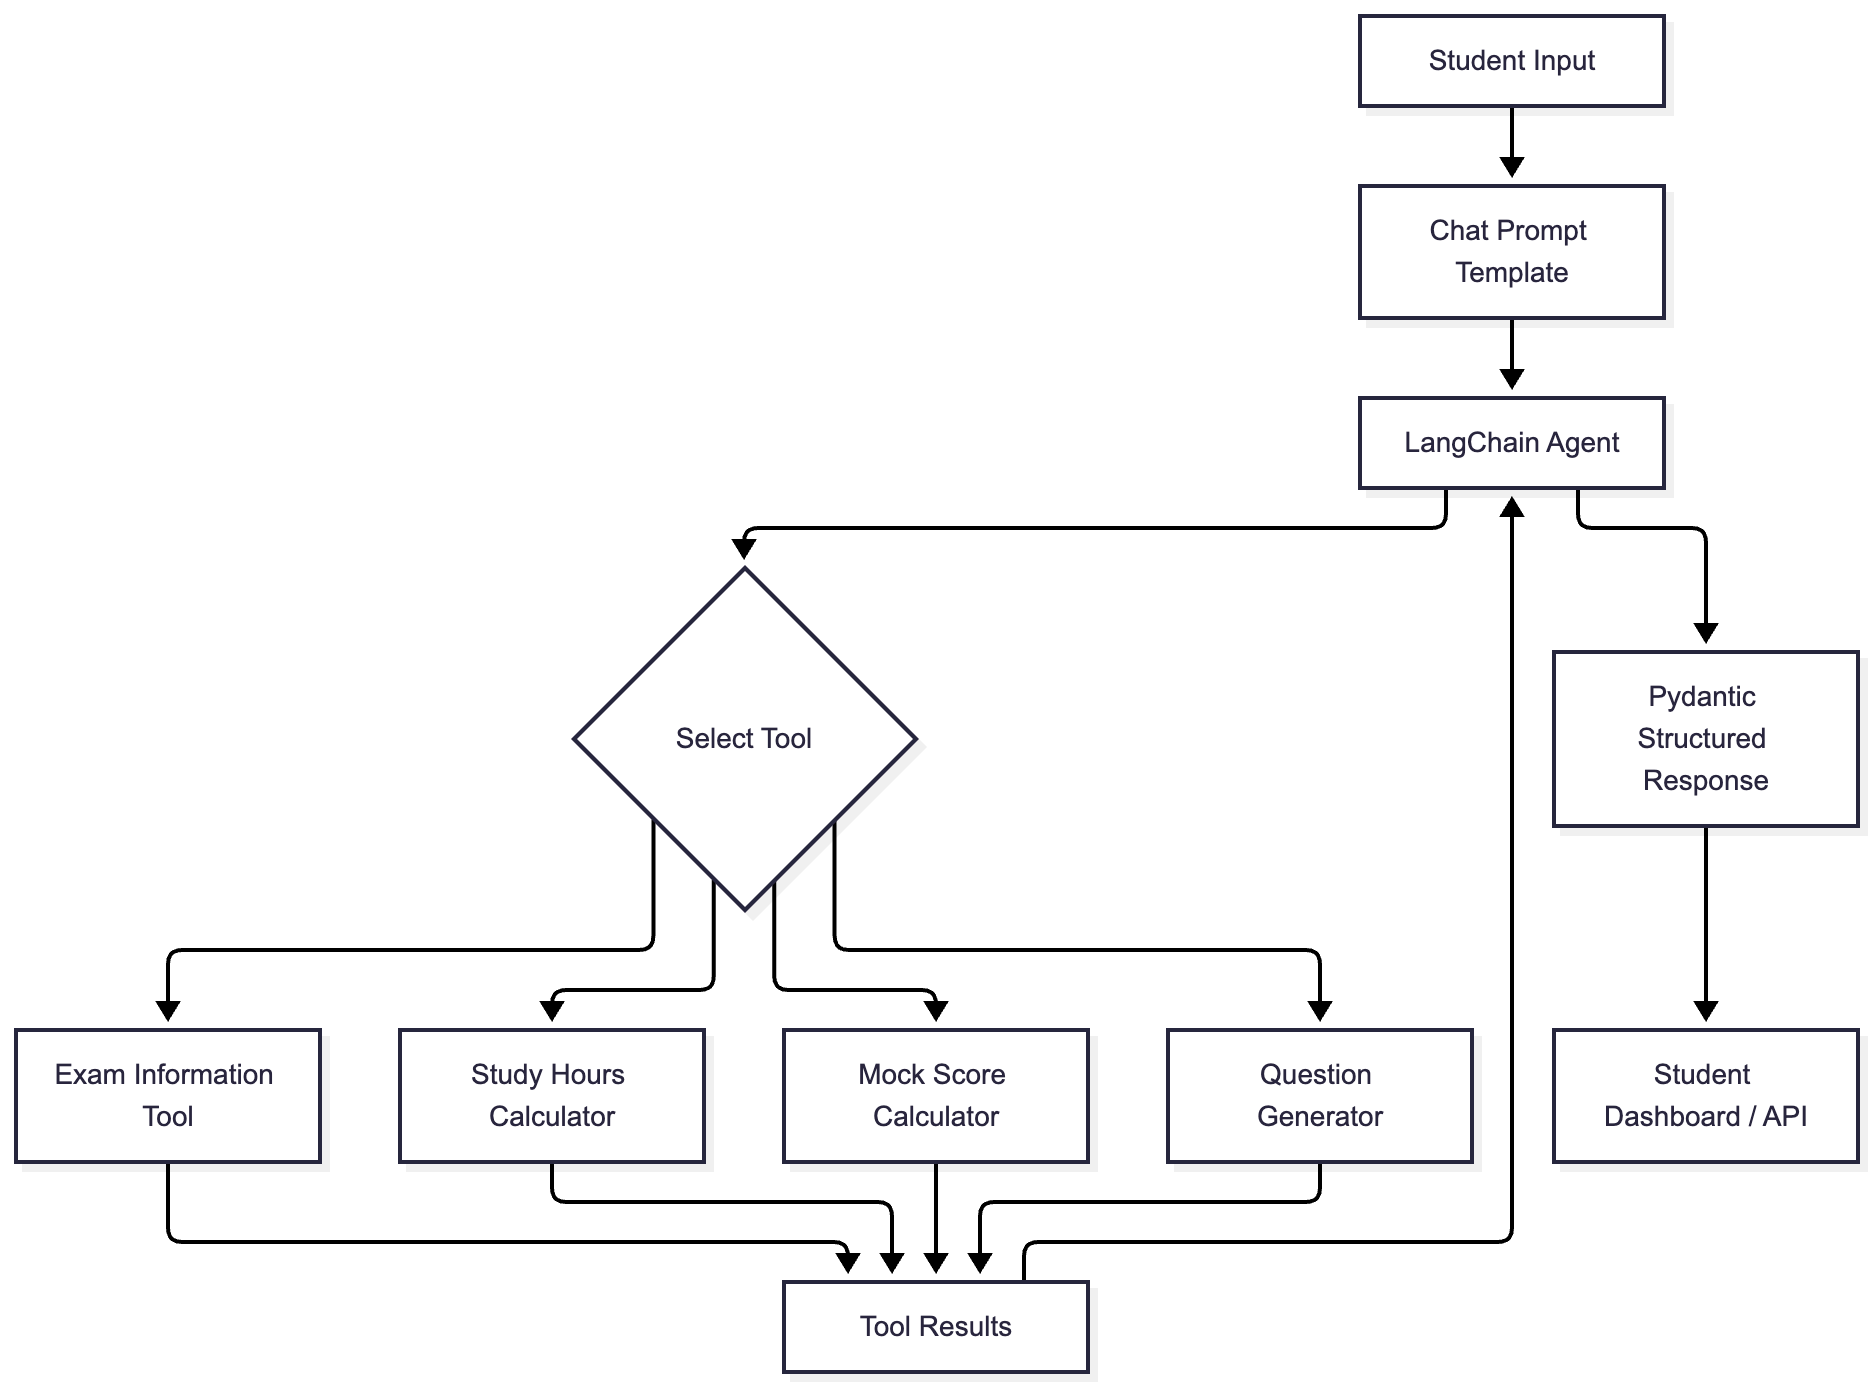

#### Capstone implementation

In [ ]:
from typing import Literal

from pydantic import BaseModel, Field
from langchain.tools import tool
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langgraph.checkpoint.memory import InMemorySaver


# 1. Model
model = ChatOpenAI(
    model=MODEL_NAME,
    api_key=OPENAI_API_KEY,
    temperature=0,
    reasoning={
        "effort": "medium"
    },
    timeout=60,
    max_retries=2
)


# 2. Tools

@tool
def exam_information(exam: str) -> str:
    """Get basic information about a supported exam."""

    data = {
        "TNPSC": "Tamil Nadu Public Service Commission",
        "UPSC": "Union Public Service Commission",
        "SSC": "Staff Selection Commission",
        "Banking": "Banking recruitment examinations"
    }

    return data.get(
        exam,
        "No information available for this exam."
    )


@tool
def study_hours(
    days_remaining: int,
    hours_per_day: float
) -> float:
    """Calculate total available study hours."""

    if days_remaining < 0 or hours_per_day < 0:
        raise ValueError("Inputs must be non-negative")

    return days_remaining * hours_per_day


@tool
def mock_score(
    obtained: float,
    total: float
) -> float:
    """Calculate mock test percentage."""

    if total <= 0:
        raise ValueError("Total marks must be positive")

    return round(obtained / total * 100, 2)


@tool
def generate_question(topic: str) -> str:
    """Generate a short practice question for a topic."""

    return (
        f"Practice question: Explain the key concepts "
        f"of {topic} and give one practical example."
    )


# 3. Output schema

class ExamCoachResponse(BaseModel):
    exam_name: str

    exam_details: str

    total_study_hours: float = Field(ge=0)

    mock_percentage: float = Field(
        ge=0,
        le=100
    )

    performance_summary: str

    practice_question: str

    recommended_next_step: str


# 4. Agent

agent = create_agent(
    model=model,
    tools=[
        exam_information,
        study_hours,
        mock_score,
        generate_question
    ],
    system_prompt="""
    You are an AI competitive exam coach.

    Use the tools to calculate study hours and
    mock-test percentage.

    Use the exam information tool for exam details.

    Generate a practice question using the question
    generation tool.

    Base calculations on the tool results.

    Do not claim to know a student's actual
    probability of clearing an exam.

    Provide practical next steps without inventing
    syllabus coverage or exam facts.
    """,
    response_format=ExamCoachResponse,
    checkpointer=InMemorySaver()
)


# 5. Execute

config = {
    "configurable": {
        "thread_id": "capstone-student-001"
    }
}

result = agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": """
                Exam: TNPSC
                Days remaining: 60
                Study hours per day: 4
                Mock marks: 380 out of 500
                Topic: Indian Polity

                Generate my exam preparation report.
                """
            }
        ]
    },
    config=config
)

# 6. Print structured output

report = result["structured_response"]

print(report.model_dump_json(indent=2))

{
  "exam_name": "TNPSC",
  "exam_details": "TNPSC stands for Tamil Nadu Public Service Commission.",
  "total_study_hours": 240.0,
  "mock_percentage": 76.0,
  "performance_summary": "You have 60 days remaining with 4 study hours per day, providing 240 total available study hours. Your mock-test score is 380 out of 500, equivalent to 76%. Use this as a current performance indicator, not as a prediction of exam success.",
  "practice_question": "Explain the key concepts of Indian Polity and give one practical example.",
  "recommended_next_step": "Spend your next study session on Indian Polity: write a structured answer to the practice question, review the relevant concepts, and record any errors or gaps. Continue taking timed mocks and analyze incorrect answers so your remaining 240 hours are focused on improvement."
}
